# Stat 220, Unit 5 Homework: When a Line Is Not Enough

`rent.csv` is 4,743 rental listings from six Indian cities. `Rent` is the monthly
rent in rupees. The predictors are `Size` (square feet), `BHK` (bedrooms), `Bathroom`, `City`,
and `FurnishingStatus`. Rent runs from Rs 1,200 to Rs 3,500,000 a month.

Run the next two cells first. The first installs what you need, and the second loads the data
everything else uses.

In [11]:
%pip install -q numpy pandas statsmodels scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\Owner\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.model_selection import train_test_split

rent = pd.read_csv("https://drbob-richardson.github.io/stat220/F2026/data/rent.csv")
RHS = "BHK + Bathroom + C(City) + C(FurnishingStatus)"
rent.head()

,BHK,Rent,Size,AreaType,City,FurnishingStatus,Preferred,Bathroom,Contact
0,2,10000,1100,Super Area,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2,20000,800,Super Area,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2,17000,1000,Super Area,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2,10000,800,Super Area,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2,7500,850,Carpet Area,Kolkata,Unfurnished,Bachelors,1,Contact Owner


**Problem 1.** *Is the line in trouble?* Fit rent on the predictors as they come.

Part a. Report the $R^2$ and the fan ratio, and paste the residual plot. The fan ratio is the spread of the residuals on the high half of the fitted values over the spread on the low half; 1 means even.

R2: 0.313   fan ratio: 4.9


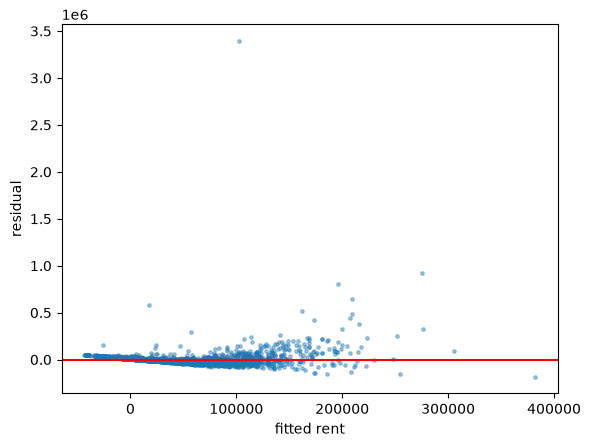

In [13]:
plain = smf.ols(f"Rent ~ Size + {RHS}", data=rent).fit()

r = pd.DataFrame({"fitted": plain.fittedvalues, "resid": plain.resid})
fan = r[r.fitted >= r.fitted.median()].resid.std() / r[r.fitted < r.fitted.median()].resid.std()
print("R2:", round(plain.rsquared, 3), "  fan ratio:", round(fan, 2))

plt.scatter(plain.fittedvalues, plain.resid, s=6, alpha=0.4)
plt.axhline(0, color="red")
plt.xlabel("fitted rent"); plt.ylabel("residual");

The R2 is .313, and the fan ratio is 4.9. The residual plot is the scatterplot generated by the code above, with fitted rent on the horizontal axis and residuals on the vertical axis.



Part b. Name the two things wrong with this residual plot, and say what each one does to the predictions.

The first problem is that the residuals spread out as the fitted rent increases, creating a fan shape. This means the model's prediction errors are less consistent for expensive apartments. The second problem is that the relationship between rent and size is not perfectly linear, and the residuals may show a curved pattern. This means the model can systematically overpredict some apartments and underpredict others rather than making random errors around zero.



**Problem 2.** *The fix.* Log both sides and look again.

Part a. Report the $R^2$ and the fan ratio for the logged model, next to the ones from problem 1.

R2: 0.77   fan ratio: 1.31
coefficient on log(Size): 0.263


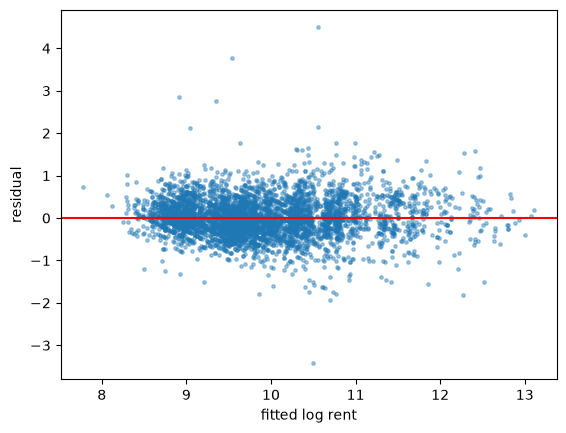

In [14]:
logged = smf.ols(f"np.log(Rent) ~ np.log(Size) + {RHS}", data=rent).fit()

r = pd.DataFrame({"fitted": logged.fittedvalues, "resid": logged.resid})
fan = r[r.fitted >= r.fitted.median()].resid.std() / r[r.fitted < r.fitted.median()].resid.std()
print("R2:", round(logged.rsquared, 3), "  fan ratio:", round(fan, 2))
print("coefficient on log(Size):", round(logged.params["np.log(Size)"], 3))

plt.scatter(logged.fittedvalues, logged.resid, s=6, alpha=0.4)
plt.axhline(0, color="red")
plt.xlabel("fitted log rent"); plt.ylabel("residual");

Original model: R2 = .313, Fan ratio = 4.9
Logged rent model: R2 = .77, fan ration = 1.31

Part b. The coefficient on `np.log(Size)` is about 0.26. Write the sentence you would give a renter: what happens to the rent when the apartment is 10% bigger, with everything else the same?

Holding the number of bedrooms, bathrooms, city, and furnishing status constant, a 10% increase in apartment size is associated with approximately a 2.6% increase in monthly rent.


Part c. The $R^2$ went from problem 1's value to this one. Explain in two sentences why those two numbers cannot be compared directly.

The first model predicts rent in rupees, while the second predicts the logarithm of rent. Because the models measure their errors on different scales, their R2 values are not directly comparable as measures of predictive performance.



**Problem 3.** *A different idea.* Grow a shallow tree on the same columns and read it.

Part a. Print the tree and report its first three splits.

In [15]:
X = pd.get_dummies(rent[["Size", "BHK", "Bathroom", "City", "FurnishingStatus"]],
                   drop_first=True)
y = np.log(rent.Rent)

tree = DecisionTreeRegressor(max_depth=3, random_state=0).fit(X, y)
print(export_text(tree, feature_names=list(X.columns), decimals=2))

|--- Bathroom <= 2.50
|   |--- City_Mumbai <= 0.50
|   |   |--- Bathroom <= 1.50
|   |   |   |--- value: [9.06]
|   |   |--- Bathroom >  1.50
|   |   |   |--- value: [9.64]
|   |--- City_Mumbai >  0.50
|   |   |--- Size <= 658.00
|   |   |   |--- value: [10.22]
|   |   |--- Size >  658.00
|   |   |   |--- value: [10.96]
|--- Bathroom >  2.50
|   |--- City_Mumbai <= 0.50
|   |   |--- Size <= 2237.50
|   |   |   |--- value: [10.32]
|   |   |--- Size >  2237.50
|   |   |   |--- value: [11.46]
|   |--- City_Mumbai >  0.50
|   |   |--- Size <= 1507.00
|   |   |   |--- value: [11.48]
|   |   |--- Size >  1507.00
|   |   |   |--- value: [12.45]



first split = Bathrooms <= 2.50, second split = City_Mumbai <= .50, third split = Siz <= 2237.50



Part b. Describe the kind of listing that lands in the most expensive leaf, and the kind that lands in the cheapest.

The most expensive has 3 or more bathrooms located in Mumbai with a size larger then 1507 square feet. The cheapest has 1 more fewer bathrooms, and is not located in Mumbai.



Part c. The tree never splits on `FurnishingStatus`. Does that mean furnishing has no effect on rent? Explain.

No. The tree not splitting on FurnishingStatus does not prove that furnishing has no effect on rent. The tree chooses splits that improve its predictions the most, and other variables may provide more useful splits at its limited depth.



**Problem 4.** *How deep should it go?*

Part a. Report the table, and say which depth you would use.

In [16]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0)

for depth in [1, 2, 4, 6, 8, 10, 12]:
    t = DecisionTreeRegressor(max_depth=depth, random_state=0).fit(Xtr, ytr)
    own = np.sqrt(((ytr - t.predict(Xtr))**2).mean())
    held = np.sqrt(((yte - t.predict(Xte))**2).mean())
    print(f"depth {depth:>2}   own rows {own:.3f}   held back {held:.3f}")

depth  1   own rows 0.759   held back 0.770
depth  2   own rows 0.597   held back 0.605
depth  4   own rows 0.461   held back 0.475
depth  6   own rows 0.405   held back 0.451
depth  8   own rows 0.366   held back 0.457
depth 10   own rows 0.319   held back 0.475
depth 12   own rows 0.282   held back 0.486


I would choose the depth with the held back value which is depth 8 with a value of .451. This depth provides the best predictive performance on the held-out data among the tested depths, rather than simply fitting the training data as closely as possible.



Part b. One column falls all the way down and the other turns around. Explain what each column is measuring and why only one of them can choose the depth.

The first column is measureing the training RMSE. The training RMSE measures the typical prediction error on the same data used to train the tree. It usually decreases as the tree gets deeper because a deeper tree can fit more detailed patterns in the training data. The second column is measureing the test RMSE. The test RMSE measures prediction error on data that the tree did not train on. It may decrease at first and then increase as the tree becomes too complex and overfits the training data.



**Problem 5.** *Let the tree inform the regression.* The tree splits on Mumbai, and then uses
a different `Size` cut inside the Mumbai branch than outside it.

Part a. Report the interaction coefficient, its p-value, and the AIC of both models.

In [17]:
rent["mumbai"] = (rent.City == "Mumbai").astype(int)
inter = smf.ols(f"np.log(Rent) ~ np.log(Size) + np.log(Size):mumbai + {RHS}", data=rent).fit()

b = inter.params["np.log(Size)"]
extra = inter.params["np.log(Size):mumbai"]
print("elasticity outside Mumbai:", round(b, 3))
print("elasticity in Mumbai     :", round(b + extra, 3))
print("p-value on the interaction:", format(inter.pvalues["np.log(Size):mumbai"], ".2g"))
print("AIC:", round(logged.aic), "->", round(inter.aic))
print("Interaction Coefficient:", round(extra, 3), "->", round(inter.params["np.log(Size):mumbai"], 3))

elasticity outside Mumbai: 0.259
elasticity in Mumbai     : 0.513
p-value on the interaction: 1.5e-16
AIC: 5889 -> 5822
Interaction Coefficient: 0.255 -> 0.255


The interaction coefficient is 0.255, the p-value is 1.5e-16. The AIC of the logged model is 5889, and the interaction model is 5822.



Part b. Write three or four sentences a property manager could use. Give the number, the units, what is being held fixed, and what they should do about it.

Outside Mumbai, a 1% increase in apartment size is associated with approximately a 0.259 change in monthly rent, holding bedrooms, bathrooms, city, and furnishing status constant. In Mumbai, the corresponding association is approximately 0.513. These estimates suggest that the relationship between apartment size and rent differs between Mumbai and the other cities. I would use these results to investigate whether Mumbai needs a different pricing model, while checking the model's predictive performance before changing rental prices.



Part c. A colleague says this proves that building bigger apartments in Mumbai causes higher rent per square foot. Explain why that is more than these listings can show, and say what they do show.

No, this does not prove that building bigger apartments in Mumbai causes higher rent per square foot. The data are observational rental listings, so other factors could influence both apartment size and rent.

